# Do omics predict breast-cancer survival better than clinical stage?
Train on **TCGA-BRCA**, test on **METABRIC**. A small public-data study, not clinical-grade.

**Question:** if we add tumour RNA (and DNA methylation) to a simple model that only knows *age + cancer stage*, do we predict overall survival better, also in a different cohort?

**Short answer:** yes against age + stage alone, but **no** once the clinical model also has ER/PR/HER2 and lymph-node status. Most of the apparent RNA gain is information the clinic already has.

This notebook reads the saved results in `results/` (the full run takes ~40 min), so it opens in seconds. To recompute everything: `python scripts/run.py`.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = "{:.3f}".format
R = "results/"
csv = lambda f: pd.read_csv(R + f)
fig = lambda f: display(Image(R + "figures/" + f))

## 1. The pipeline in 5 steps
1. **Download** public data (TCGA RNA/methylation/survival, METABRIC RNA/clinical) → `src/data.py`
2. **Clean** into cohorts: women, primary tumour, stage I–IV → `src/data.py`
3. **Models**: clinical Cox (the baseline), CoxNet, Random Survival Forest, DeepSurv, MOFA+ → `src/models.py`
4. **Evaluate**: C-index, AUC, Brier score, calibration → `src/evaluate.py`
5. **Run all of it**: internal cross-validation, then external validation → `scripts/run.py`

Feature sets: **C** = age + stage, **C+R** = C + 2000 genes, **C+R+M** = C+R + 5000 methylation sites (internal only; METABRIC has no methylation).

## 2. The data

In [2]:
csv("data_summary.csv")

,cohort,n,deaths,deaths_within_5y,median_followup_censored_y,age_median,stage_I,stage_II,stage_III,stage_IV
0,"TCGA-BRCA, RNA (external training set)",1045,139,94,2.140,58.000,181,603,242,19
1,"TCGA-BRCA, RNA + methylation (internal CV cohort)",759,94,68,2.100,58.000,125,429,195,10
2,METABRIC (external test set),1454,821,307,13.710,61.220,501,825,118,10


Survival by stage looks as expected in both cohorts (higher stage, worse survival). TCGA follow-up is short (median 2.1 years), METABRIC is long (13.7).

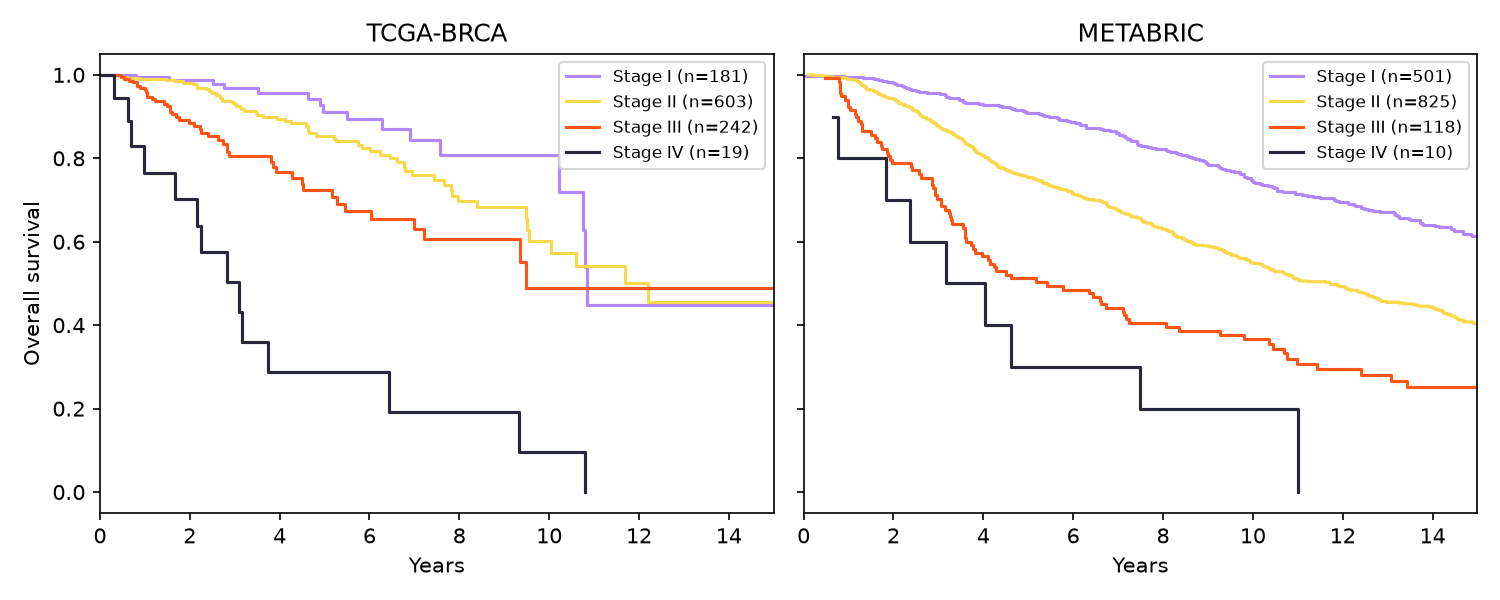

In [3]:
fig("km_by_stage.png")

In [4]:
csv("clinical_cox_hr.csv")  # hazard ratios of the age + stage baseline

,cohort,term,HR
0,TCGA-BRCA,age per 10 y,1.439
1,TCGA-BRCA,stage II vs I,1.828
2,TCGA-BRCA,stage III vs I,3.734
3,TCGA-BRCA,stage IV vs I,11.304
4,METABRIC,age per 10 y,1.391
5,METABRIC,stage II vs I,1.672
6,METABRIC,stage III vs I,2.956
7,METABRIC,stage IV vs I,4.764


## 3. Internal validation (TCGA, 3 × 5-fold cross-validation)
Higher Uno C / AUC is better, lower IBS is better. With only 68 deaths within 5 years the spread between folds (±) is bigger than any difference between models.

In [5]:
s = csv("cv_summary.csv")
s[["run", "C_uno_5y_mean", "C_uno_5y_std", "AUC_5y_mean", "IBS_1_5y_mean"]]

,run,C_uno_5y_mean,C_uno_5y_std,AUC_5y_mean,IBS_1_5y_mean
0,cox|C,0.706,0.068,0.710,0.072
1,rsf|C,0.592,0.078,0.588,0.082
2,deepsurv|C,0.694,0.065,0.696,0.073
3,coxnet|C+R,0.711,0.063,0.716,0.073
4,rsf|C+R,0.657,0.054,0.661,0.080
5,deepsurv|C+R,0.673,0.067,0.670,0.077
6,mofa|C+R,0.722,0.054,0.731,0.073
7,coxnet|C+R+M,0.695,0.053,0.703,0.076
8,rsf|C+R+M,0.653,0.060,0.657,0.080
9,deepsurv|C+R+M,0.665,0.068,0.670,0.078


## 4. External validation (fit on TCGA, test on METABRIC)

In [6]:
csv("external_metrics.csv")[["run", "C_uno_5y", "AUC_3y", "AUC_5y", "IBS_1_5y", "calibration_slope", "O/E_5y"]]

,run,C_uno_5y,AUC_3y,AUC_5y,IBS_1_5y,calibration_slope,O/E_5y
0,cox|C,0.623,0.613,0.639,0.095,0.834,1.293
1,rsf|C,0.581,0.617,0.588,0.097,0.243,1.293
2,deepsurv|C,0.664,0.667,0.685,0.094,0.895,1.248
3,coxnet|C+R,0.671,0.688,0.689,0.093,0.428,1.201
4,rsf|C+R,0.625,0.626,0.640,0.096,0.575,1.314
5,deepsurv|C+R,0.611,0.638,0.619,0.095,0.425,1.292
6,mofa|C+R,0.670,0.681,0.687,0.092,0.679,1.307


Difference vs the clinical Cox (`cox|C`). The bars are 95% intervals: if they cross 0, the gain is not distinguishable from noise.
CoxNet and MOFA+ with RNA beat the baseline by ~+0.05 C-index, but DeepSurv on age + stage alone also gains +0.04, so part of that gain is not about RNA.

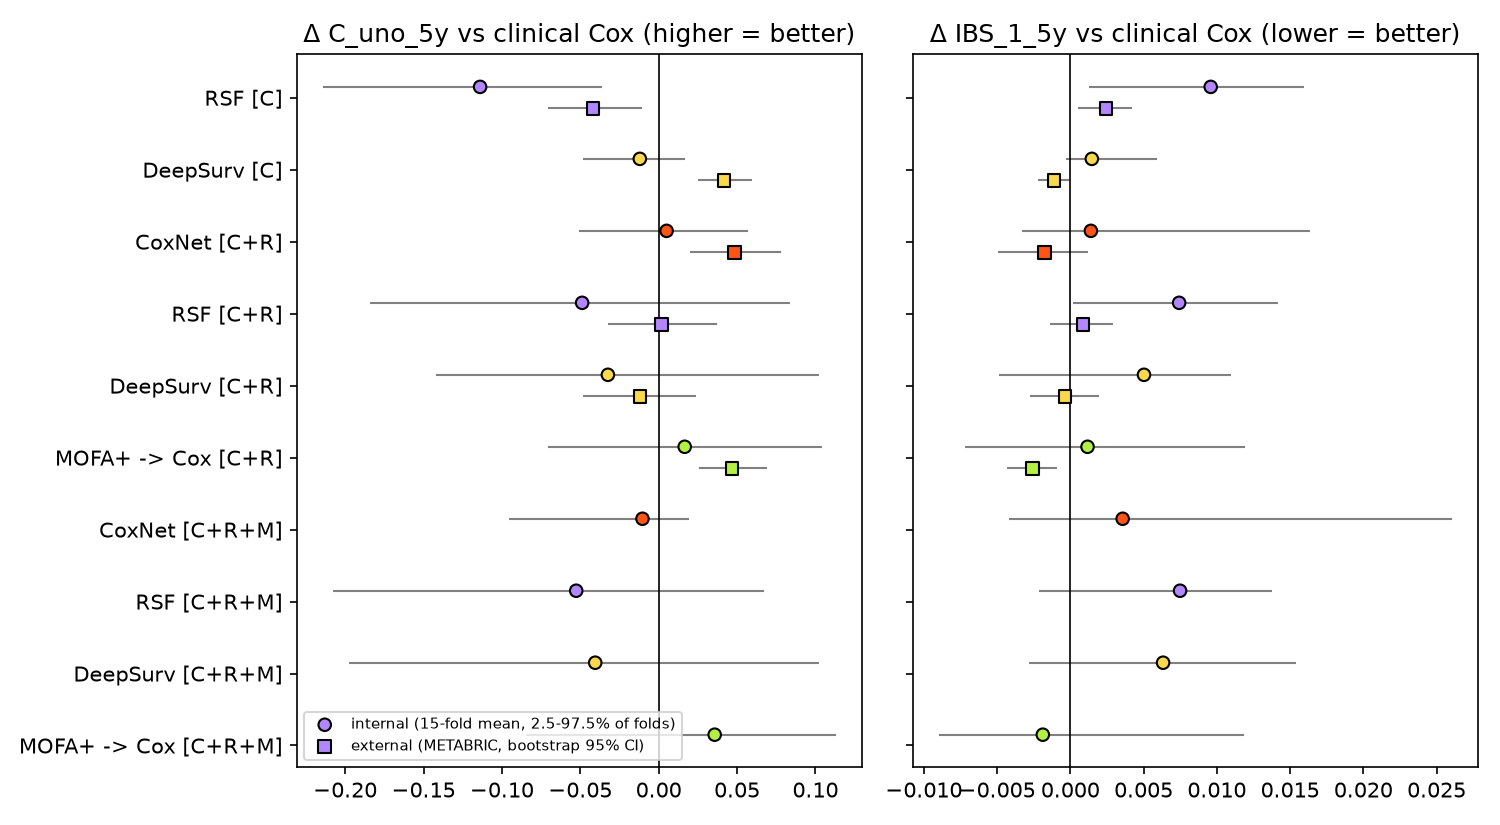

In [7]:
fig("deltas_forest.png")

### Time-dependent AUC and calibration in METABRIC

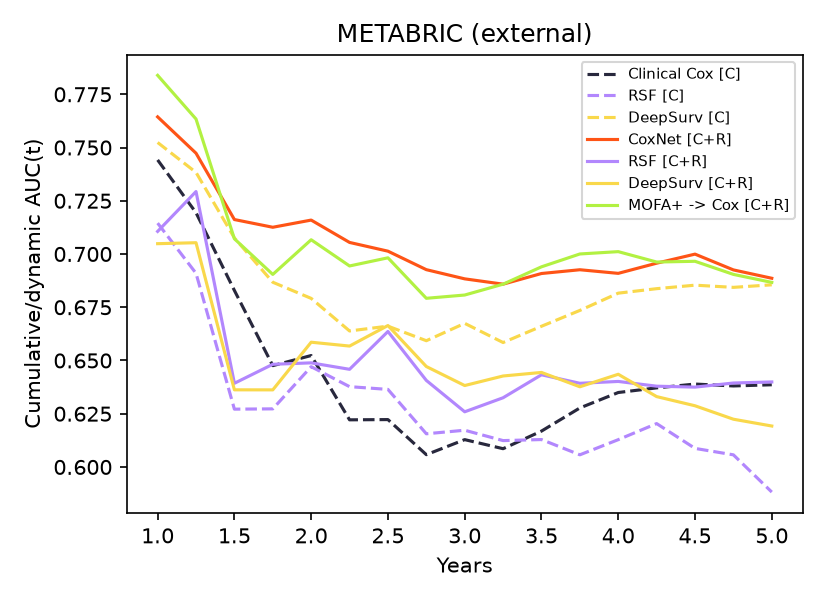

In [8]:
fig("td_auc_metabric.png")

Every model under-predicts 5-year risk in METABRIC (O/E > 1), and the omic models are over-dispersed (slope < 1). No recalibration was done, on purpose.

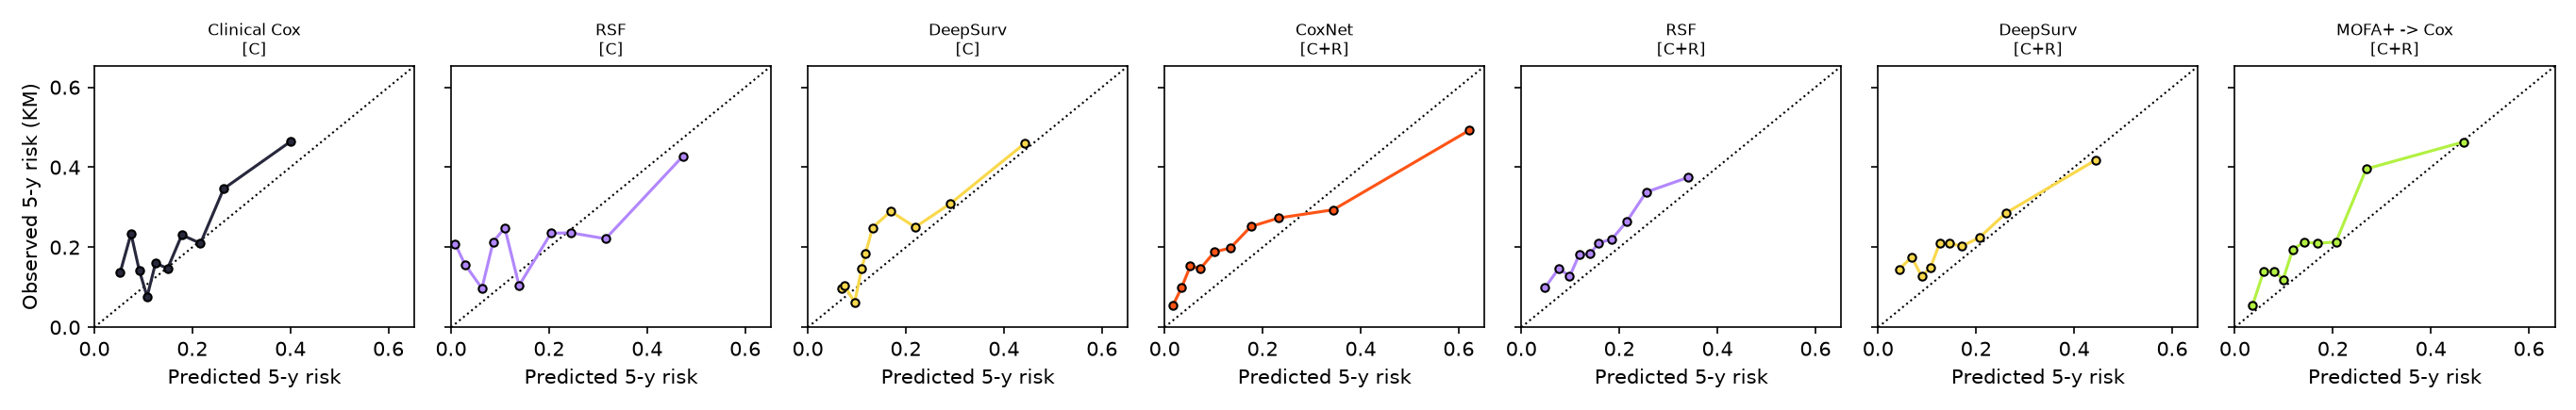

In [9]:
fig("calibration_metabric.png")

## 5. Sanity check
Same cross-validation with the omics rows shuffled between patients. If a model still "gains" here, the gain is fake.

In [10]:
csv("sanity.csv")

,run,metric,mean,std
0,coxnet|C+R,AUC_3y,-0.012,0.017
1,coxnet|C+R,AUC_5y,0.012,0.016
2,coxnet|C+R,C_harrell,-0.004,0.015
3,coxnet|C+R,C_uno_5y,0.007,0.012
4,coxnet|C+R,IBS_1_5y,-0.001,0.001
5,deepsurv|C,AUC_3y,0.009,0.031
6,deepsurv|C,AUC_5y,0.000,0.025
7,deepsurv|C,C_harrell,0.007,0.005
8,deepsurv|C,C_uno_5y,0.002,0.016
9,deepsurv|C,IBS_1_5y,0.002,0.002


## 6. Follow-up (post hoc): other endpoint, richer clinical model
Survival can be overall (OS) or disease-specific (DSS). The baseline can be *age + stage* or *rich* (+ ER, PR, HER2, nodes, age²). Uno C in METABRIC:

In [11]:
f = csv("followup_metrics.csv")
f.pivot_table(index="run", columns=["endpoint", "baseline"], values="C_uno_5y")

endpoint         DSS              OS      
baseline   age+stage  rich age+stage  rich
run                                       
coxnet|C+R       NaN   NaN     0.644 0.692
cox|C          0.641 0.725     0.613 0.693
deepsurv|C     0.577 0.657     0.657 0.627
mofa|C+R       0.708 0.715     0.651 0.691

With the rich baseline a plain linear Cox is as good as any RNA model (ΔC between -0.010 and -0.001, intervals span 0). CoxNet did not converge on DSS and is reported as missing.

In [12]:
d = csv("followup_deltas.csv")
d[d.metric == "C_uno_5y"].drop(columns=["ref", "metric"]).round(3)

,endpoint,baseline,run,est,lo,hi
3,OS,age+stage,coxnet|C+R,0.032,-0.001,0.061
8,OS,age+stage,deepsurv|C,0.045,0.024,0.067
13,OS,age+stage,mofa|C+R,0.038,0.017,0.060
18,OS,age+stage,coxnet|C+R,-0.013,-0.045,0.018
23,OS,age+stage,cox|C,-0.045,-0.067,-0.024
28,OS,age+stage,mofa|C+R,-0.006,-0.033,0.022
33,OS,rich,coxnet|C+R,-0.001,-0.022,0.020
38,OS,rich,deepsurv|C,-0.066,-0.090,-0.042
43,OS,rich,mofa|C+R,-0.002,-0.022,0.017
48,OS,rich,coxnet|C+R,0.065,0.032,0.096


## 7. Conclusions and limits
- RNA beats age + stage externally, but adds nothing over a richer clinical Cox.
- Methylation never helped.
- Few TCGA events, RNA-seq vs microarray shift, minimal tuning, and the follow-up was designed after seeing the main results.

Full methods and every number: see [README.md](README.md). Short abstract: [SUMMARY.md](SUMMARY.md).